# Graph statistics

Extra statistics for the graph built by `pnews.graph` (items, sources, entities). The build step writes basic counts to `report/tables/graph_<version>_stats.md`; this notebook adds:

1. Node and edge counts, density
2. Degree distributions
3. Connectivity: components, path lengths, the item–item projection
4. Centrality: degree, betweenness, closeness, eigenvector, PageRank
5. Homophily: do items link mostly within their own source?
6. Chi-square tests: source × entity type, entity type × shared/single-item

The graph is rebuilt here from `data/items.jsonl`, `data/enrichment/entities.jsonl` and `config/`, the same way `pnews.graph` builds it, so no saved `.pt` file is needed. Ratings are not read.

In [3]:
import os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

if Path.cwd().name == "notebooks":  # run from the repo root so config/ and data/ resolve
    os.chdir("..")

from pnews import graph
from pnews.collect import load_feeds
from pnews.content import load_items

cfg = yaml.safe_load(Path("config/graph.yml").read_text())
SEED = cfg["seed"]
data, nodes = graph.build_graph(
    load_items(Path("data/items.jsonl")),
    graph.load_entity_rows(Path("data/enrichment/entities.jsonl")),
    load_feeds(Path("config/feeds.yml")),
    cfg.get("min_entity_items", 1),
)
G = graph.to_networkx(data, nodes, seed=SEED)  # undirected; node ids "item:…", "source:…", "entity:…"

TYPES = ("item", "source", "entity")
ntype = nx.get_node_attributes(G, "node_type")
label = nx.get_node_attributes(G, "label")
by_type = {t: [n for n in G if ntype[n] == t] for t in TYPES}
pd.set_option("display.max_colwidth", 70)
print(f"graph {cfg['version']}: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

graph v0: 780 nodes, 902 edges


## 1. Nodes, edges, density

In [4]:
rel = Counter(d["relation"] for _, _, d in G.edges(data=True))
n_item, n_src, n_ent = (len(by_type[t]) for t in TYPES)

nodes_df = pd.DataFrame({"nodes": {t: len(by_type[t]) for t in TYPES}})
nodes_df.loc["total"] = nodes_df["nodes"].sum()

edges_df = pd.DataFrame({
    "edges (one direction)": {"item → source (from)": rel["from"], "item → entity (mentions)": rel["mentions"]},
    "possible": {"item → source (from)": n_item * n_src, "item → entity (mentions)": n_item * n_ent},
})
edges_df["density"] = (edges_df["edges (one direction)"] / edges_df["possible"]).round(4)
edges_df.loc["total"] = [G.number_of_edges(), np.nan, np.nan]

overall = pd.Series({
    "edges in the PyG graph (with reverse edges)": 2 * G.number_of_edges(),
    "density, whole graph (all node pairs)": round(nx.density(G), 5),
    "mean degree, whole graph": round(2 * G.number_of_edges() / G.number_of_nodes(), 2),
    "self-loops": nx.number_of_selfloops(G),
})
display(nodes_df, edges_df, overall.to_frame("value"))

,nodes
item,45
source,9
entity,726
total,780


,edges (one direction),possible,density
item → source (from),45,405.0,0.1111
item → entity (mentions),857,32670.0,0.0262
total,902,NaN,NaN


,value
edges in the PyG graph (with reverse edges),1804.00000
"density, whole graph (all node pairs)",0.00297
"mean degree, whole graph",2.31000
self-loops,0.00000


Density over all node pairs is misleading for a graph where edges only run between certain node types. The per-relation density (edges ÷ possible item–entity or item–source pairs) is the more useful number. Item–source density is always 1/number of sources, because every item has exactly one source.

## 2. Degree distributions

In [5]:
deg = dict(G.degree())
item_mentions = {n: deg[n] - 1 for n in by_type["item"]}  # minus the one edge to its source
degree_df = pd.DataFrame({
    "entities per item": pd.Series(item_mentions).describe(),
    "items per entity": pd.Series({n: deg[n] for n in by_type["entity"]}).describe(),
    "items per source": pd.Series({n: deg[n] for n in by_type["source"]}).describe(),
}).round(2)
display(degree_df)

ent_deg = pd.Series({n: deg[n] for n in by_type["entity"]})
print("entities by number of items:", dict(sorted(Counter(ent_deg).items())))
print(f"skew: entities per item {stats.skew(list(item_mentions.values())):.2f}, items per entity {stats.skew(ent_deg):.2f}")

,entities per item,items per entity,items per source
count,45.00,726.00,9.0
mean,19.04,1.18,5.0
std,27.77,0.74,0.0
min,0.00,1.00,5.0
25%,8.00,1.00,5.0
50%,12.00,1.00,5.0
75%,22.00,1.00,5.0
max,185.00,10.00,5.0


entities by number of items: {1: 654, 2: 48, 3: 10, 4: 7, 5: 1, 6: 3, 7: 1, 9: 1, 10: 1}
skew: entities per item 4.90, items per entity 6.73


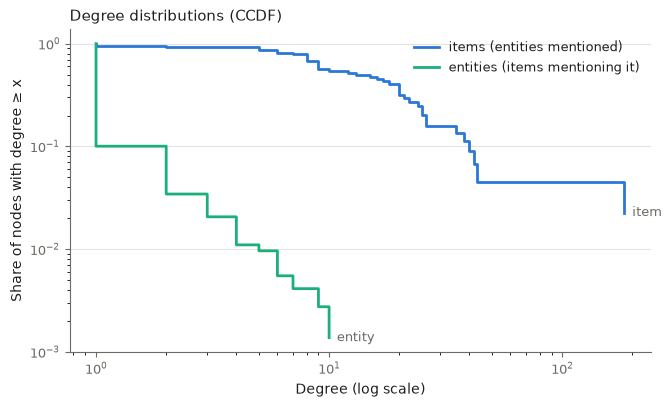

In [6]:
# Complementary CDF on log-log axes: share of nodes with degree >= x.
fig, ax = plt.subplots(figsize=(7.5, 4.2), facecolor="white")
for t, values, name in [("item", item_mentions.values(), "items (entities mentioned)"),
                        ("entity", ent_deg.values, "entities (items mentioning it)")]:
    x = np.sort([v for v in values if v > 0])
    y = 1 - np.arange(len(x)) / len(x)
    ax.step(x, y, where="post", color=graph.COLORS[t], linewidth=2, label=name)
    ax.text(x[-1] * 1.08, y[-1], t, color=graph.INK_MUTED, fontsize=9, va="center")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Degree (log scale)", color=graph.INK)
ax.set_ylabel("Share of nodes with degree ≥ x", color=graph.INK)
ax.set_title("Degree distributions (CCDF)", color=graph.INK, fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, labelcolor=graph.INK)
graph._style(ax)
plt.show()

## 3. Connectivity

In [7]:
comps = sorted(nx.connected_components(G), key=len, reverse=True)
comp_df = pd.DataFrame([{
    "nodes": len(c),
    **{t: sum(ntype[n] == t for n in c) for t in TYPES},
    "sources": ", ".join(sorted(G.nodes[n]["source_id"] for n in c if ntype[n] == "source")),
} for c in comps])
display(comp_df)

giant = G.subgraph(comps[0])
print(f"largest component: {giant.number_of_nodes()} of {G.number_of_nodes()} nodes")
print(f"  diameter {nx.diameter(giant)}, average shortest path {nx.average_shortest_path_length(giant):.2f}")
print("  (item → entity → item is 2 hops, so the item-to-item distance is half these values)")

,nodes,item,source,entity,sources
0,770,40,8,722,"bbc_us_canada, cloudflare, coding_horror, deepmind, nature, openai..."
1,10,5,1,4,hackernoon


largest component: 770 of 780 nodes
  diameter 10, average shortest path 5.53
  (item → entity → item is 2 hops, so the item-to-item distance is half these values)


### Item–item projection

Two items are linked if they mention the same entity. The edge weight is the number of shared entities. This is the structure a graph model can use beyond "same source".

In [8]:
bip = G.subgraph(by_type["item"] + by_type["entity"])
P = nx.bipartite.weighted_projected_graph(bip, by_type["item"])
for n in P:
    P.nodes[n]["source_id"] = G.nodes[n]["source_id"]

p_comps = sorted((len(c) for c in nx.connected_components(P)), reverse=True)
within = sum(P.nodes[a]["source_id"] == P.nodes[b]["source_id"] for a, b in P.edges)
weights = [d["weight"] for *_, d in P.edges(data=True)]
proj = pd.Series({
    "items": P.number_of_nodes(),
    "item pairs linked": P.number_of_edges(),
    "  within the same source": within,
    "  across sources": P.number_of_edges() - within,
    "density": round(nx.density(P), 4),
    "isolated items": nx.number_of_isolates(P),
    "component sizes": p_comps,
    "shared entities per linked pair (mean)": round(np.mean(weights), 2) if weights else 0,
    "shared entities per linked pair (max)": max(weights, default=0),
    "average clustering": round(nx.average_clustering(P), 3),
    "transitivity": round(nx.transitivity(P), 3),
})
display(proj.to_frame("value"))
print("bipartite clustering (item–entity graph), items:", round(nx.bipartite.average_clustering(bip, by_type["item"]), 3),
      "entities:", round(nx.bipartite.average_clustering(bip, by_type["entity"]), 3))

,value
items,45
item pairs linked,164
within the same source,57
across sources,107
density,0.1657
isolated items,6
component sizes,"[37, 2, 1, 1, 1, 1, 1, 1]"
shared entities per linked pair (mean),1.69
shared entities per linked pair (max),11
average clustering,0.563


bipartite clustering (item–entity graph), items: 0.057 entities: 0.815


## 4. Centrality

Computed on the whole undirected graph (all node types). Eigenvector centrality is computed on the largest component only, because it is not well defined across disconnected parts; nodes outside it get 0.

- **degree**: share of other nodes a node touches
- **betweenness**: share of shortest paths passing through the node (bridges between sources)
- **closeness**: inverse mean distance to reachable nodes (scaled by the reachable share)
- **eigenvector / PageRank**: being linked to well-linked nodes

In [9]:
eig = dict.fromkeys(G, 0.0)
eig.update(nx.eigenvector_centrality(giant, max_iter=2000, tol=1e-8))
cent = pd.DataFrame({
    "type": ntype,
    "label": label,
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G, wf_improved=True),
    "eigenvector": eig,
    "pagerank": nx.pagerank(G, alpha=0.85),
})
MEASURES = ["degree", "betweenness", "closeness", "eigenvector", "pagerank"]
fmt = {m: "{:.4f}" for m in MEASURES}

print("Mean centrality by node type")
display(cent.groupby("type")[MEASURES].mean().style.format(fmt))
for t in TYPES:
    print(f"Top 10 {t} nodes by betweenness")
    display(cent[cent["type"] == t].nlargest(10, "betweenness")[["label", *MEASURES]].style.format(fmt))

Mean centrality by node type


,degree,betweenness,closeness,eigenvector,pagerank
type,,,,,
entity,0.0015,0.0017,0.1790,0.0132,0.0007
item,0.0257,0.0589,0.1820,0.0161,0.0103
source,0.0064,0.0582,0.1803,0.0059,0.0024


Top 10 item nodes by betweenness


,label,degree,betweenness,closeness,eigenvector,pagerank
item:e960e8891f7d7ad8,Genie 4: A new generation of world simulation,0.2388,0.4127,0.2190,0.7071,0.1097
item:3e32bae570ff21ee,Gemini 4 Carbon: Our next frontier model,0.0218,0.2786,0.2632,0.0043,0.0092
item:1ec832c6e37ca98a,The Pulse: Firebase’s global outage & poor response,0.0526,0.1952,0.2649,0.0001,0.0182
item:ff7415f4aed24317,The Pulse: Time to rethink software security because of AI?,0.0565,0.1866,0.2707,0.0000,0.0204
item:1750855042e8ceec,Gemini Omni 1.2 Flash: Fast and cost-effective with longer clips,0.0205,0.1543,0.2346,0.0043,0.0085
item:4b114a749b9a1589,Every Choice Changes Everything: The Show,0.0244,0.1048,0.2296,0.0000,0.0099
item:a4e259590fe62746,The Trump coalition is shattered - what will Republicans do now?,0.0501,0.0902,0.2389,0.0000,0.0175
item:457e0dbd4bb6e46c,The Pulse: Anthropic builds its own source control system,0.0552,0.0898,0.2353,0.0000,0.0199
item:2ca64e51ee736fcb,The Pulse: RoR creator sparks new “death of coding by hand” debate,0.0462,0.0807,0.2257,0.0000,0.0164
item:7b1007320043c0b9,"Medicinal plants, lessons from mushrooms and the power of smell: Books in brief",0.0231,0.0737,0.1923,0.0000,0.0099


Top 10 source nodes by betweenness


,label,degree,betweenness,closeness,eigenvector,pagerank
source:deepmind,Google DeepMind Blog,0.0064,0.3869,0.2474,0.0531,0.0026
source:nature,Nature,0.0064,0.0381,0.1696,0.0000,0.0026
source:coding_horror,Coding Horror,0.0064,0.0374,0.1887,0.0000,0.0025
source:bbc_us_canada,BBC News US & Canada,0.0064,0.0165,0.2064,0.0000,0.0021
source:pragmatic_engineer,The Pragmatic Engineer,0.0064,0.0136,0.2302,0.0000,0.0021
source:stripe,Stripe Blog,0.0064,0.0135,0.2078,0.0000,0.0023
source:cloudflare,Cloudflare Blog,0.0064,0.0103,0.1798,0.0000,0.0024
source:openai,OpenAI News,0.0064,0.0075,0.1847,0.0000,0.0023
source:hackernoon,HackerNoon,0.0064,0.0001,0.0080,0.0000,0.0030


Top 10 entity nodes by betweenness


,label,degree,betweenness,closeness,eigenvector,pagerank
entity:location:united states,United States,0.0128,0.4152,0.2893,0.0003,0.0042
entity:organization:google,Google,0.0064,0.1208,0.2589,0.0003,0.0022
entity:organization:openai,OpenAI,0.0116,0.0986,0.2374,0.0000,0.0039
entity:organization:cloudflare,Cloudflare,0.0077,0.0855,0.2266,0.0000,0.0028
entity:location:china,China,0.0039,0.0715,0.2278,0.0000,0.0014
entity:organization:meta,Meta,0.0077,0.0611,0.2337,0.0000,0.0026
entity:location:united kingdom,United Kingdom,0.0051,0.0493,0.2109,0.0000,0.0018
entity:organization:stripe,Stripe,0.0090,0.0491,0.2296,0.0000,0.0030
entity:product:exploitgym,ExploitGym,0.0026,0.0308,0.2289,0.0003,0.0011
entity:product:google ads,Google Ads,0.0026,0.0288,0.2371,0.0003,0.0010


In [10]:
# How far do the measures agree? Spearman rank correlation over entities in 2+ items.
# (Entities in one item are leaves: betweenness 0 and degree 1 for all of them, so they
# would only add ties and push the degree/betweenness correlation to 1.)
ent_c = cent[(cent["type"] == "entity") & (cent.index.map(deg) >= 2)][MEASURES]
rho, _ = stats.spearmanr(ent_c)
print(f"{len(ent_c)} entities")
display(pd.DataFrame(rho, index=MEASURES, columns=MEASURES).round(2))

72 entities


,degree,betweenness,closeness,eigenvector,pagerank
degree,1.00,0.66,0.49,0.47,0.84
betweenness,0.66,1.00,0.56,0.40,0.73
closeness,0.49,0.56,1.00,0.86,0.26
eigenvector,0.47,0.40,0.86,1.00,0.22
pagerank,0.84,0.73,0.26,0.22,1.00


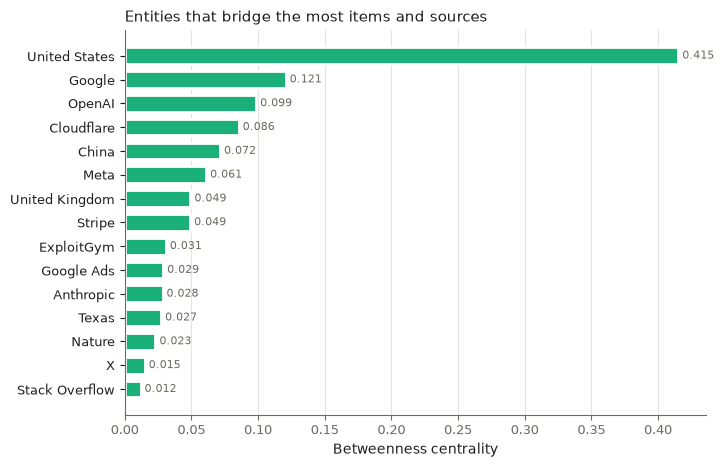

In [11]:
top = cent[cent["type"] == "entity"].nlargest(15, "betweenness").iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5), facecolor="white")
ax.barh(top["label"], top["betweenness"], color=graph.COLORS["entity"], height=0.7, edgecolor="white", linewidth=2)
for y, v in enumerate(top["betweenness"]):
    ax.text(v, y, f" {v:.3f}", va="center", fontsize=8, color=graph.INK_MUTED)
ax.set_xlabel("Betweenness centrality", color=graph.INK)
ax.set_title("Entities that bridge the most items and sources", color=graph.INK, fontsize=11, loc="left")
graph._style(ax)
ax.yaxis.grid(False); ax.xaxis.grid(True, color=graph.GRID, linewidth=0.8)
ax.tick_params(axis="y", colors=graph.INK)
plt.show()

### Items most connected to other items (projection)

In [12]:
item_c = pd.DataFrame({
    "source": nx.get_node_attributes(P, "source_id"),
    "title": {n: label[n] for n in P},
    "linked items": dict(P.degree()),
    "shared entities (weighted degree)": dict(P.degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(P),
})
display(item_c.sort_values(["linked items", "shared entities (weighted degree)"], ascending=False).head(10)
        .style.format({"betweenness": "{:.3f}"}))

,source,title,linked items,shared entities (weighted degree),betweenness
item:ff7415f4aed24317,pragmatic_engineer,The Pulse: Time to rethink software security because of AI?,24,44,0.155
item:1ec832c6e37ca98a,pragmatic_engineer,The Pulse: Firebase’s global outage & poor response,22,52,0.130
item:e72d79c0a899ffe6,stripe,Stripe on Stripe: What we learned moving $1B in vendor payments to Global Payouts,17,24,0.051
item:37bc35888138e969,pragmatic_engineer,The Pulse: new trend of building “internal vibe-coding apps” at tech companies,16,37,0.024
item:457e0dbd4bb6e46c,pragmatic_engineer,The Pulse: Anthropic builds its own source control system,14,37,0.014
item:c2c6c70a58eee1d2,bbc_us_canada,"'Dana, please take the job!' - Trump asks UFC boss to be White House press secretary",14,29,0.017
item:2ca64e51ee736fcb,pragmatic_engineer,The Pulse: RoR creator sparks new “death of coding by hand” debate,13,32,0.015
item:b00606b7d715372d,stripe,Trends from Money20/20 2026: The rise of “hidden” financial services,13,17,0.012
item:a4e259590fe62746,bbc_us_canada,The Trump coalition is shattered - what will Republicans do now?,12,35,0.016
item:68e33a6af1fcdd54,bbc_us_canada,"With Stephen Miller pick, Trump readies for a battle",12,34,0.016


## 5. Homophily: do items link within their own source?

The **attribute assortativity** of the projection by `source_id` runs from −1 to 1: 1 means items only link to items from the same source, 0 means links ignore the source.

A **permutation test** checks whether the share of within-source links is higher than chance. Source labels are shuffled across items (the graph is kept), and the within-source share is recomputed each time. The p-value is the share of shuffles that reach the observed value. Shuffles are seeded from `config/graph.yml`.

In [13]:
r_src = nx.attribute_assortativity_coefficient(P, "source_id")
edges = list(P.edges)
idx = {n: k for k, n in enumerate(P)}
a = np.array([idx[u] for u, _ in edges]); b = np.array([idx[v] for _, v in edges])
labels = np.array([P.nodes[n]["source_id"] for n in P])

def within_share(lab):
    return float(np.mean(lab[a] == lab[b])) if len(edges) else float("nan")

observed = within_share(labels)
rng = np.random.default_rng(SEED)
null = np.array([within_share(rng.permutation(labels)) for _ in range(5000)])
p_value = (np.sum(null >= observed) + 1) / (len(null) + 1)

display(pd.Series({
    "source assortativity (projection)": round(r_src, 3),
    "within-source share of links, observed": round(observed, 3),
    "within-source share, shuffled mean": round(null.mean(), 3),
    "permutation p-value (one-sided, 5000 shuffles)": round(p_value, 4),
    "degree assortativity, whole graph": round(nx.degree_assortativity_coefficient(G), 3),
}).to_frame("value"))

,value
source assortativity (projection),0.2200
"within-source share of links, observed",0.3480
"within-source share, shuffled mean",0.0910
"permutation p-value (one-sided, 5000 shuffles)",0.0002
"degree assortativity, whole graph",-0.2710


Pairs of items are not independent (one item takes part in many pairs), so a chi-square test on pair counts would overstate significance. The permutation test keeps the graph fixed and avoids that problem.

## 6. Chi-square tests

Both tests use `scipy.stats.chi2_contingency`. Effect size is **Cramér's V** (0 = no association, 1 = complete). Chi-square assumes expected counts of at least 5 in most cells, so the share of cells below 5 is reported. The heatmaps show **adjusted standardized residuals**: about ±2 or more means that cell has clearly more (red) or fewer (blue) entities than independence predicts.

**Counting unit.** Each distinct (source, entity) pair is counted once. Counting mentions instead would let one long article dominate. For example, the DeepMind post with a contributor list mentions 184 people.

In [14]:
def chi_square(table: pd.DataFrame, name: str) -> pd.DataFrame:
    table = table.loc[table.sum(axis=1) > 0, table.sum(axis=0) > 0]
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    display(pd.Series({"chi2": round(chi2, 2), "dof": dof, "p-value": f"{p:.2e}", "n": int(n),
                       "Cramér's V": round(v, 3),
                       "cells with expected < 5": f"{(expected < 5).mean():.0%}"}, name=name).to_frame())
    rows = table.sum(axis=1).to_numpy()[:, None] / n
    cols = table.sum(axis=0).to_numpy()[None, :] / n
    return pd.DataFrame((table - expected) / np.sqrt(expected * (1 - rows) * (1 - cols)),
                        index=table.index, columns=table.columns)

DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

def residual_heatmap(res: pd.DataFrame, title: str):
    lim = max(3.0, float(np.abs(res.to_numpy()).max()))
    fig, ax = plt.subplots(figsize=(1.3 * res.shape[1] + 2.5, 0.42 * res.shape[0] + 1.4), facecolor="white")
    im = ax.imshow(res, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
    for (i, j), v in np.ndenumerate(res.to_numpy()):
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color=graph.INK)
    ax.set_xticks(range(res.shape[1]), res.columns); ax.set_yticks(range(res.shape[0]), res.index)
    ax.tick_params(colors=graph.INK, labelsize=9, length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    fig.colorbar(im, ax=ax, label="adjusted residual", shrink=0.8)
    ax.set_title(title, color=graph.INK, fontsize=11, loc="left")
    plt.show()

# Distinct (source, entity) pairs with the entity's type.
pairs = {(G.nodes[i]["source_id"], e) for i, e in G.edges if ntype[i] == "item" and ntype[e] == "entity"} | \
        {(G.nodes[i]["source_id"], e) for e, i in G.edges if ntype[i] == "item" and ntype[e] == "entity"}
pairs_df = pd.DataFrame([{"source": s, "entity": e, "type": G.nodes[e]["entity_type"]} for s, e in pairs])

### Test 1: does the mix of entity types depend on the source?

H₀: entity type is independent of source.

type,location,organization,person,product
source,,,,
bbc_us_canada,32,23,33,10
cloudflare,1,7,6,53
coding_horror,7,9,10,13
deepmind,5,7,184,33
hackernoon,0,2,0,2
nature,7,13,16,19
openai,5,14,5,38
pragmatic_engineer,6,51,16,74
stripe,10,19,6,23


,source × entity type
chi2,441.35
dof,24
p-value,2.32e-78
n,759
Cramér's V,0.44
cells with expected < 5,14%


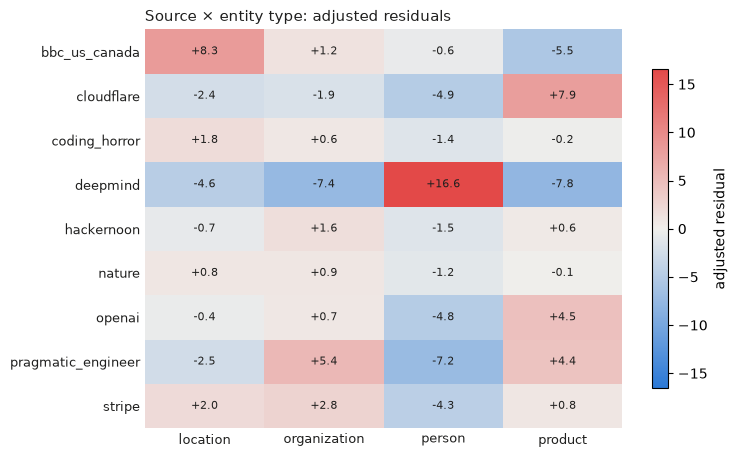

In [15]:
t1 = pd.crosstab(pairs_df["source"], pairs_df["type"])
display(t1)
res1 = chi_square(t1, "source × entity type")
residual_heatmap(res1, "Source × entity type: adjusted residuals")

In [16]:
# Sensitivity: drop the item with the most entities (a contributor list) and test again.
outlier = max(item_mentions, key=item_mentions.get)
print(f"dropping {outlier} ({G.nodes[outlier]['source_id']}, {item_mentions[outlier]} entities): {label[outlier][:70]}")
keep = {(G.nodes[i]["source_id"], e) for i in by_type["item"] if i != outlier for e in G.neighbors(i) if ntype[e] == "entity"}
t1b = pd.crosstab(*zip(*[(s, G.nodes[e]["entity_type"]) for s, e in keep]), rownames=["source"], colnames=["type"])
_ = chi_square(t1b, "source × entity type, without the outlier item")

dropping item:e960e8891f7d7ad8 (deepmind, 185 entities): Genie 4: A new generation of world simulation


,"source × entity type, without the outlier item"
chi2,164.78
dof,24
p-value,5.67e-23
n,574
Cramér's V,0.309
cells with expected < 5,14%


### Test 2: are some entity types more likely to link items?

An entity helps the graph only when 2 or more items mention it. Each entity is counted once.

H₀: being shared is independent of entity type.

shared,1 item,2+ items,share in 2+ items
type,,,
location,52,12,0.188
organization,116,20,0.147
person,269,7,0.025
product,217,33,0.132


,entity type × shared
chi2,28.93
dof,3
p-value,2.32e-06
n,726
Cramér's V,0.2
cells with expected < 5,0%


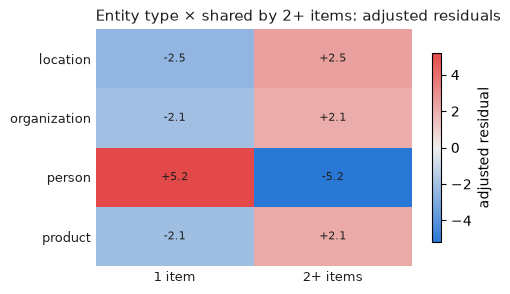

In [17]:
ent_df = pd.DataFrame({"type": {e: G.nodes[e]["entity_type"] for e in by_type["entity"]},
                       "shared": {e: "2+ items" if deg[e] >= 2 else "1 item" for e in by_type["entity"]}})
t2 = pd.crosstab(ent_df["type"], ent_df["shared"])
t2["share in 2+ items"] = (t2["2+ items"] / t2.sum(axis=1)).round(3)
display(t2)
res2 = chi_square(t2[["1 item", "2+ items"]], "entity type × shared")
residual_heatmap(res2, "Entity type × shared by 2+ items: adjusted residuals")

## 7. Reading the results

Written for the v0 graph on the 45-item sample (5 items per source, built 2026-11-08). Rerun the notebook after the graph grows; these numbers will change.

- **Sparse, long-tailed.** 857 of 32,670 possible item–entity edges exist (2.6%). 654 of 726 entities (90%) appear in one item only, and only 72 link two or more items. Both degree distributions are strongly right-skewed (skew 4.9 and 6.7).
- **One large component.** 770 of 780 nodes are connected. HackerNoon (summary-only text) forms its own component. The longest shortest path is 10 hops and the mean is 5.5, which is about 2–3 item-to-item steps.
- **Items cluster.** 164 item pairs share an entity, and 6 items share none. The projection's clustering coefficient (0.56) shows that linked items form tight groups.
- **One outlier distorts centrality.** The DeepMind "Genie 4" post (185 entities, mostly a contributor list) has the highest item degree, eigenvector and PageRank. It also makes DeepMind the top source by betweenness. Eigenvector centrality is almost entirely concentrated on this one star (0.71), so it is not informative until contributor lists are handled. Among entities, **United States** is the main bridge (betweenness 0.42), followed by Google, OpenAI, Cloudflare and China. Among entities in 2+ items the measures only partly agree: degree vs PageRank ρ = 0.84, eigenvector vs PageRank ρ = 0.22.
- **Source homophily is real but partial.** 35% of item links stay within a source, against 9% expected by chance (permutation p ≈ 0.0002; assortativity 0.22). Still, 65% of links cross sources, so entity edges carry information the source alone does not.
- **Chi-square 1 (source × entity type): strong association.** χ² = 441, df = 24, Cramér's V = 0.44. Without the Genie 4 post: V = 0.31, p ≈ 6e-23. Sources differ in what they talk about. For example, Cloudflare and OpenAI mention mostly products, and BBC accounts for the most locations. 14% of cells have expected counts below 5, which is within the usual 20% rule of thumb.
- **Chi-square 2 (entity type × shared): people rarely link items.** Only 2.5% of person entities appear in 2+ items, against 13–19% for the other types (χ² = 28.9, df = 3, p ≈ 2e-6, V = 0.20). People add 269 dead-end nodes. This supports one of the open options for contributor lists: a prompt rule, a cap, or `min_entity_items: 2`.

Caveat: with 5 items per source these are descriptive results for this sample, not stable estimates.